In [ ]:
!pip install import-ipynb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 21.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [import-ipynb]


In [ ]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import math
import random
import itertools


In [ ]:
import graip_pro_nuevo as gpn
import graip_dirigido_nuevo as gdn

Tipos de graphlets ng=4: 8 ['Cuña (P3)', 'Triángulo (K3)', 'Estrella (K1,3)', 'Camino (P4)', 'Paleta (paw)', 'Ciclo (C4)', 'Diamante', 'Completo (K4)']
Tipos de graphlets ng=5: 29
Karate club: {'Cuña (P3)': 393, 'Triángulo (K3)': 45, 'Estrella (K1,3)': 1098, 'Camino (P4)': 681, 'Paleta (paw)': 452, 'Ciclo (C4)': 36, 'Diamante': 85, 'Completo (K4)': 11}
Verificaciones OK
Tipos de graphlets dirigidos ng=3: 13
Tipos de graphlets dirigidos ng=4: 212
Karate Club (Dirigido) - Primeros 5 graphlets: [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]
¡Todas las verificaciones dirigidas OK!


## funcion

In [ ]:
def GraphGenerator_animar(SAMPLE, ng=None, maxs=10000, node_step=5, w=2/3, maxrej=None, K=2,
                   seed=None, verbose=1000):
    """
    Algorithm 1: generador incremental GRAIP (Modificado para animación).
    """
    cat = SAMPLE["cat"]
    if ng is not None and ng != cat["ng"]:
        raise ValueError("ng no coincide con el usado en Sample")
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    En, sn, Em, sm = SAMPLE["En"], SAMPLE["sn"], SAMPLE["Em"], SAMPLE["sm"]
    Ec = np.asarray(SAMPLE["Ec"], dtype=float)
    sc = np.asarray(SAMPLE["sc"], dtype=float)
    CCg = SAMPLE["CCg"]
    bins, Ep, sp = gpn.objetivos_grado(SAMPLE)
    if maxrej is None:
        maxrej = max(10, int(round(0.02 * Em)))

    n0 = max(3, int(round(En / 5)))
    m0 = max(1, int(round(Em / 5)))
    m_ba = max(1, min(n0 - 1, int(round(m0 / n0))))
    H = nx.barabasi_albert_graph(n0, m_ba, seed=seed)
    proximo_id = n0

    def proporciones(Gr):
        return gpn.Histogram([d for _, d in Gr.degree()], bins) / max(Gr.number_of_nodes(), 1)

    PH = proporciones(H)
    CH = gpn.contar_graphlets(H, cat)
    costH = gpn.Cost(PH, CH, Ep, sp, Ec, sc, w, En)
    rechazos = 0

    # 1. Añadimos 'graphs' y 'actions' al diccionario de historial
    history = {
        'steps': [], 'CH_trajectory': [], 'PG_hist_trajectory': [],
        'n_trajectory': [], 'm_trajectory': [], 'cost_trajectory': [],
        'graphs': [], 'actions': [],  # <-- NUEVO para animación
        'Ep': Ep, 'sp': sp, 'Ec': Ec, 'sc': sc, 'bins': bins, 'K': K,
        'nombres': cat['nombres'], 'exito': False,
    }

    # 2. Actualizamos registrar para guardar el grafo y el estado de la acción
    def registrar(paso, accion_actual=None, accepted=False):
        history['steps'].append(paso)
        history['CH_trajectory'].append(CH.tolist())
        history['PG_hist_trajectory'].append(PH.tolist())
        history['n_trajectory'].append(H.number_of_nodes())
        history['m_trajectory'].append(H.number_of_edges())
        history['cost_trajectory'].append(costH)
        if accepted:
          history['graphs'].append(H.copy())  # Guardamos una copia exacta del grafo en este paso
          history['actions'].append({'accion': accion_actual, 'accepted': accepted})

    for step in range(1, maxs + 1):
        if gpn.dentro_de_limites(PH, CH, Ep, sp, Ec, sc, K):
            history['exito'] = True
            print(f'ÉXITO en el paso {step}: n={H.number_of_nodes()}, m={H.number_of_edges()}')
            return H, history

        n = H.number_of_nodes()
        m = H.number_of_edges()
        r = random.random()
        accion = None

        if step % node_step == 0:
            if r > gpn._f_logistica(n, En, sn):
                accion = ("add_node", (proximo_id, gpn.AddNode(H, CCg, proximo_id)))
            elif n > 3:
                u = random.choice(list(H.nodes()))
                accion = ("remove_node", (u, list(H.adj[u])))
        else:
            m_escalado = m * En / n if n > 0 else 0.0
            if r > gpn._f_logistica(m_escalado, Em, sm):
                par = gpn.arista_ausente_al_azar(H)
                if par is not None:
                    accion = ("add_edge", par)
            elif m > 0:
                accion = ("remove_edge", random.choice(list(H.edges())))

        if accion is None:
            # Si no hubo acción en este paso, puedes optar por registrar o saltar
            continue

        dC = gpn.aplicar_cambio(H, accion, cat)
        CT = CH + dC
        PT = proporciones(H)
        costT = gpn.Cost(PT, CT, Ep, sp, Ec, sc, w, En)

        accepted = False
        if costT < costH or rechazos >= maxrej:
            CH, PH, costH = CT, PT, costT
            rechazos = 0
            accepted = True
            if accion[0] == "add_node":
                proximo_id += 1
        else:
            gpn.deshacer_cambio(H, accion)
            rechazos += 1

        # 3. Registramos el estado y la acción evaluada en este paso
        registrar(step, accion, accepted)

        if verbose and step % verbose == 0:
            print(f'paso {step}: n={H.number_of_nodes()}, m={H.number_of_edges()}, costo={costH:.4f}')

    print(f'No convergió en {maxs} pasos (costo final {costH:.4f}).')
    return H, history

In [ ]:
def GraphGenerator_dirigido_animar(SAMPLE, ng=None, maxs=10000, node_step=5, w=2/3, maxrej=None, K=2,
                                   seed=None, verbose=1000, indexes=None):
    """
    Algoritmo 1: generador incremental GRAIP adaptado para grafos dirigidos (DiGraph) con soporte de animación.
    """
    cat = SAMPLE["cat"]
    if ng is not None and ng != cat["ng"]:
        raise ValueError("ng no coincide con el usado en Sample")
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    En, sn, Em, sm = SAMPLE["En"], SAMPLE["sn"], SAMPLE["Em"], SAMPLE["sm"]
    Ec = SAMPLE["Ec"]
    sc = SAMPLE["sc"]
    CCg = SAMPLE["CCg"]

    if indexes is not None:
        Ec = {i: Ec[i] for i in range(len(Ec)) if i in indexes}
        sc = {i: sc[i] for i in range(len(sc)) if i in indexes}

    bins, Ep, sp = gdn.objetivos_grado(SAMPLE)
    if maxrej is None:
        maxrej = max(10, int(round(0.02 * Em)))

    # Semilla: grafo BA convertido a DiGraph
    n0 = max(3, int(round(En / 5)))
    m0 = max(1, int(round(Em / 5)))
    m_ba = max(1, min(n0 - 1, int(round(m0 / n0))))
    H = nx.DiGraph(nx.barabasi_albert_graph(n0, m_ba, seed=seed))
    proximo_id = n0

    def proporciones(Gr):
        return gdn.Histogram([d for _, d in Gr.degree()], bins) / max(Gr.number_of_nodes(), 1)

    PH = proporciones(H)
    CH = gdn.contar_graphlets_dirigidos(H, cat)
    costH = gdn.Cost(PH, CH, Ep, sp, Ec, sc, w, En)
    rechazos = 0

    # Diccionario de historial extendido con 'graphs' y 'actions'
    history = {
        'steps': [], 'CH_trajectory': [], 'PG_hist_trajectory': [],
        'n_trajectory': [], 'm_trajectory': [], 'cost_trajectory': [],
        'graphs': [], 'actions': [],  # <--- NUEVO para animación
        'Ep': Ep, 'sp': sp, 'Ec': Ec, 'sc': sc, 'bins': bins, 'K': K,
        'nombres': cat['nombres'], 'exito': False,
    }

    def registrar(paso, accion_actual=None, accepted=False):
        history['steps'].append(paso)
        history['CH_trajectory'].append(CH)
        history['PG_hist_trajectory'].append(PH.tolist())
        history['n_trajectory'].append(H.number_of_nodes())
        history['m_trajectory'].append(H.number_of_edges())
        history['cost_trajectory'].append(costH)
        if accepted:
          history['graphs'].append(H.copy())  # Guardamos copia exacta del DiGraph
          history['actions'].append({'accion': accion_actual, 'accepted': accepted})

    for step in range(1, maxs + 1):
        if gdn.dentro_de_limites(PH, CH, Ep, sp, Ec, sc, K):
            history['exito'] = True
            print(f'ÉXITO en el paso {step}: n={H.number_of_nodes()}, m={H.number_of_edges()}')
            # Registrar el paso final de éxito
            registrar(step, accion_actual=None, accepted=True)
            return H, history

        n = H.number_of_nodes()
        m = H.number_of_edges()
        r = random.random()
        accion = None

        if step % node_step == 0:
            if r > gdn._f_logistica(n, En, sn):
                accion = ("add_node", (proximo_id, gdn.AddNode_dirigido(H, CCg, proximo_id)))
            elif n > 3:
                u = random.choice(list(H.nodes()))
                arcos_conectados = list(H.in_edges(u)) + list(H.out_edges(u))
                accion = ("remove_node", (u, arcos_conectados))
        else:
            m_escalado = m * En / n if n > 0 else 0.0
            if r > gdn._f_logistica(m_escalado, Em, sm):
                par = gdn.arco_ausente_al_azar(H)
                if par is not None:
                    accion = ("add_edge", par)
            elif m > 0:
                accion = ("remove_edge", random.choice(list(H.edges())))

        if accion is None:
            continue

        dC = gdn.aplicar_cambio_dirigido(H, accion, cat)
        if indexes is not None:
            CT = {i: CH[i] + dC[i] for i in indexes}
        else:
            CT = {i: CH[i] + dC[i] for i in range(len(CH))}

        PT = proporciones(H)
        costT = gdn.Cost(PT, CT, Ep, sp, Ec, sc, w, En)

        accepted = False
        if costT < costH or rechazos >= maxrej:
            CH, PH, costH = CT, PT, costT
            rechazos = 0
            accepted = True
            if accion[0] == "add_node":
                proximo_id += 1
        else:
            gdn.deshacer_cambio_dirigido(H, accion)
            rechazos += 1

        # Registrar el paso con su respectiva acción y resultado
        registrar(step, accion, accepted)

        if verbose and step % verbose == 0:
            print(f'paso {step}: n={H.number_of_nodes()}, m={H.number_of_edges()}, costo={costH:.4f}')

    registrar(maxs + 1, accion_actual=None, accepted=False)
    print(f'No convergió en {maxs} pasos (costo final {costH:.4f}).')
    return H, history

##animacion g1

In [ ]:
# ==========================================
# 8. EJEMPLO DE PRUEBA
# ==========================================
np.random.seed(0)
seed_G = nx.karate_club_graph()

# Convertirlo en una red probabilística
for u in seed_G.nodes():
    seed_G.nodes[u]['prob'] = 1
for u, v in seed_G.edges():
    seed_G[u][v]["prob"] = np.random.rand() * 0.7 + 0.3

G = seed_G
S = 1000      # el paper usa 10 000 muestras
ng = 4

SAMPLE = gpn.Sample(G, S, ng, seed=0)
print(f"En = {SAMPLE['En']:.2f} ± {SAMPLE['sn']:.2f}   Em = {SAMPLE['Em']:.2f} ± {SAMPLE['sm']:.2f}   CCg = {SAMPLE['CCg']:.3f}")
for nombre, e, s in zip(SAMPLE["cat"]["nombres"], SAMPLE["Ec"], SAMPLE["sc"]):
    print(f"  {nombre:18s} Ec = {e:8.1f}  ± 2sc = {2*s:7.1f}")

En = 31.31 ± 1.60   Em = 50.28 ± 3.96   CCg = 0.153
  Cuña (P3)          Ec =    188.3  ± 2sc =    56.8
  Triángulo (K3)     Ec =     11.3  ± 2sc =     8.3
  Estrella (K1,3)    Ec =    365.2  ± 2sc =   209.3
  Camino (P4)        Ec =    311.3  ± 2sc =   121.0
  Paleta (paw)       Ec =    100.5  ± 2sc =    78.1
  Ciclo (C4)         Ec =     14.2  ± 2sc =    12.5
  Diamante           Ec =     10.6  ± 2sc =    13.4
  Completo (K4)      Ec =      0.6  ± 2sc =     2.0


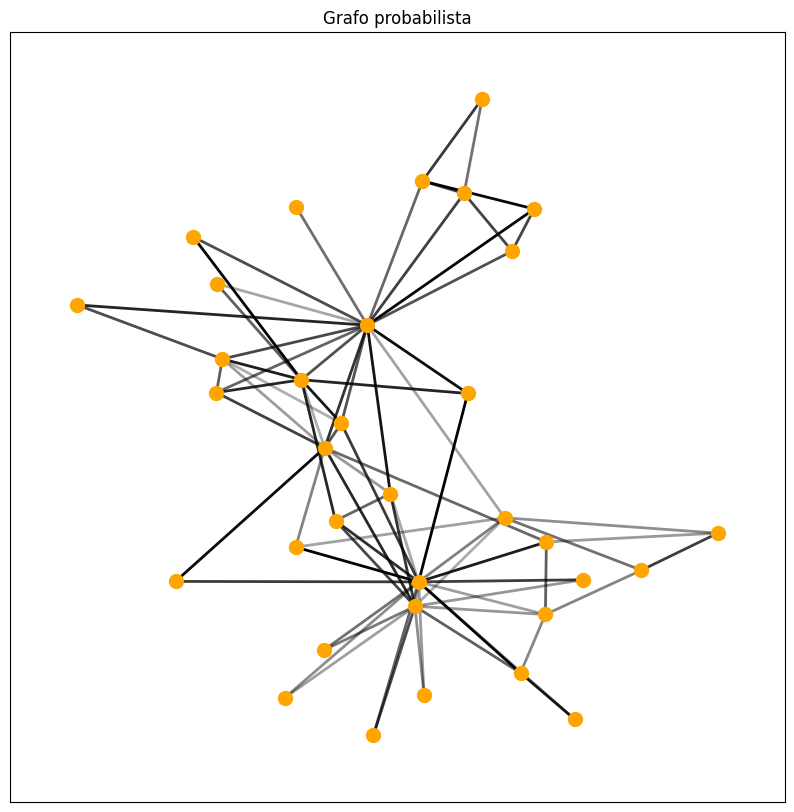

In [ ]:
pesos_aristas = [seed_G[u][v]["prob"] for u, v,data in seed_G.edges(data=True)]

plt.figure(figsize=(10, 10))
plt.title('Grafo probabilista')
nx.draw_networkx_nodes(seed_G,nx.spring_layout(seed_G, seed=42,k=0.14),node_color="orange",node_size=100)
nx.draw_networkx_edges(seed_G,nx.spring_layout(seed_G, seed=42,k=0.14),alpha=pesos_aristas,edge_color='black',width=2)
plt.show()

In [ ]:
# Ejecutar GraphGenerator con los parámetros recomendados en el paper
# (node_step = 5, w = 2/3, maxrej = 0.02·Em, intervalo E ± 2s)
synthetic_H, history_data = GraphGenerator_animar(
    SAMPLE, ng, maxs=20000, node_step=5, w=0.5, maxrej=None, K=2, seed=0, verbose=2000
)

ÉXITO en el paso 88: n=23, m=38


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import networkx as nx

# 1. Extraer la lista de grafos del historial
graphs = history_data['graphs']
steps = history_data['steps']

print(f"Total de frames guardados para animar: {len(graphs)}")

# 2. Configurar la figura de Matplotlib
fig, ax = plt.subplots(figsize=(8, 8))

# 3. Calcular un layout fijo basado en el ÚLTIMO grafo (para que la estructura no "baile")
# Usamos el grafo final para encontrar las posiciones globales de todos los nodos que aparecieron
pos_global = nx.spring_layout(graphs[-1], seed=42, k=0.15)

def update(frame_idx):
    ax.clear()
    G_current = graphs[frame_idx]
    step_actual = steps[frame_idx]

    # Para asegurar que si un nodo es muy nuevo y no está en pos_global, no dé error:
    # (Aunque lo ideal es calcular el layout con el grafo final)
    pos = {node: pos_global[node] for node in G_current.nodes() if node in pos_global}

    # Si algún nodo es nuevo y no estaba en el final, le asignamos una posición temporal
    for node in G_current.nodes():
        if node not in pos:
            pos[node] = (0.0, 0.0)

    # Dibujar el grafo actual
    nx.draw_networkx_nodes(G_current, pos, ax=ax, node_size=100, node_color='blue')
    nx.draw_networkx_edges(G_current, pos, ax=ax, alpha=1, edge_color='gray', width=2)

    # Mostrar información en el título de la animación
    n_nodos = G_current.number_of_nodes()
    n_aristas = G_current.number_of_edges()
    costo_actual = history_data['cost_trajectory'][frame_idx]

    ax.set_title(f"Paso: {step_actual} | Nodos: {n_nodos} | Aristas: {n_aristas} | Costo: {costo_actual:.4f}", fontsize=12)
    ax.axis('off')

# 4. Crear la animación (interval controla la velocidad en milisegundos entre frames)
ani = animation.FuncAnimation(fig, update, frames=len(graphs), interval=200, repeat=False)

plt.close(fig) # Evita que se dibuje una figura estática extra al final del script

# 5. Renderizar y reproducir la animación en Google Colab
HTML(ani.to_html5_video())

Total de frames guardados para animar: 41


##animacion coli-dirigido

In [ ]:
# 3. Cárgalo de vuelta a NetworkX
G_core = nx.read_graphml('/content/grafo_proteinas_probabilista6.graphml')
print(
    f"✨ ¡Grafo cargado exitosamente! Nodos: {G_core.number_of_nodes()},"
    f" Aristas: {G_core.number_of_edges()}"
)

✨ ¡Grafo cargado exitosamente! Nodos: 484, Aristas: 676


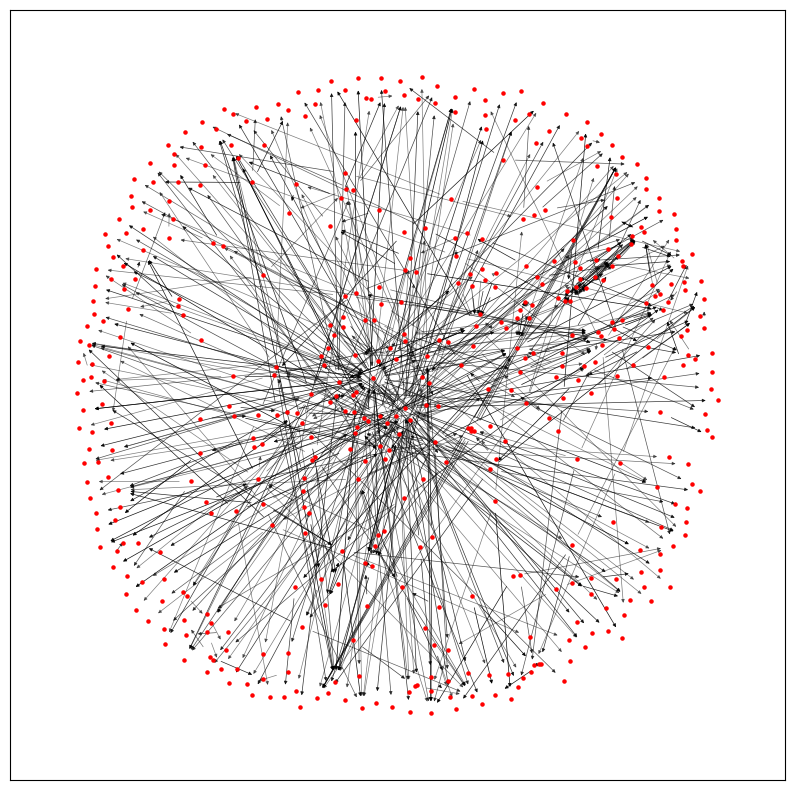

In [ ]:
pesos_aristas = [G_core[u][v]["prob"] for u, v,data in G_core.edges(data=True)]

plt.figure(figsize=(10, 10))
nx.draw_networkx_nodes(G_core,nx.spring_layout(G_core, seed=42,k=0.15),node_color="red",node_size=5)
nx.draw_networkx_edges(G_core,nx.spring_layout(G_core, seed=42,k=0.15),alpha=pesos_aristas,edge_color='black',width=0.5,arrowsize=5)
plt.show()

In [ ]:
G = G_core
S = 1000      # el paper usa 10 000 muestras
ng = 3

SAMPLE = gdn.Sample_dirigido(G, S, ng, seed=0)
print(f"En = {SAMPLE['En']:.2f} ± {SAMPLE['sn']:.2f}   Em = {SAMPLE['Em']:.2f} ± {SAMPLE['sm']:.2f}   CCg = {SAMPLE['CCg']:.3f}")
for nombre, e, s in zip(SAMPLE["cat"]["nombres"], SAMPLE["Ec"], SAMPLE["sc"]):
    print(f"  {nombre:18s} Ec = {e:8.1f}  ± 2sc = {2*s:7.1f}")

En = 321.56 ± 22.14   Em = 405.97 ± 26.37   CCg = 0.006
  Estrella de salida (Fuente central) Ec =      0.0  ± 2sc =     0.0
  Graphlet k=3, 2 arcos (Desconocido) Ec =      1.0  ± 2sc =     2.0
  Graphlet k=3, 2 arcos (Desconocido) Ec =      2.0  ± 2sc =     4.0
  Graphlet k=3, 3 arcos (Desconocido) Ec =      3.0  ± 2sc =     6.0
  Feed-Forward Loop (FFL parcial) Ec =      4.0  ± 2sc =     8.0
  Graphlet k=3, 3 arcos (Desconocido) Ec =      5.0  ± 2sc =    10.0
  Ciclo dirigido de 3 (C3) Ec =      6.0  ± 2sc =    12.0
  Tríada cuasi-completa A Ec =      7.0  ± 2sc =    14.0
  Graphlet k=3, 4 arcos (Desconocido) Ec =      8.0  ± 2sc =    16.0
  Graphlet k=3, 4 arcos (Desconocido) Ec =      9.0  ± 2sc =    18.0
  Graphlet k=3, 4 arcos (Desconocido) Ec =     10.0  ± 2sc =    20.0
  Graphlet k=3, 5 arcos (Desconocido) Ec =     11.0  ± 2sc =    22.0
  K3 totalmente bidireccional (Completo recíproco) Ec =     12.0  ± 2sc =    24.0


In [ ]:
# Ejecutar GraphGenerator con los parámetros recomendados en el paper
# (node_step = 5, w = 2/3, maxrej = 0.02·Em, intervalo E ± 2s)
synthetic_H, history_data = GraphGenerator_dirigido_animar(
    SAMPLE, ng,  maxs=24000, node_step=5, w=0.5, maxrej=100, K=2, seed=0, verbose=2000
)

paso 2000: n=243, m=297, costo=0.1140
paso 4000: n=273, m=339, costo=0.0888
paso 6000: n=273, m=341, costo=0.0513
paso 8000: n=273, m=338, costo=0.0112
paso 10000: n=284, m=350, costo=0.0152
paso 12000: n=287, m=350, costo=0.0133
paso 14000: n=286, m=352, costo=0.0126
paso 16000: n=287, m=351, costo=0.0136
paso 18000: n=296, m=364, costo=0.0161
paso 20000: n=309, m=377, costo=0.0136
paso 22000: n=314, m=382, costo=0.0136
paso 24000: n=323, m=397, costo=0.0117
No convergió en 24000 pasos (costo final 0.0117).


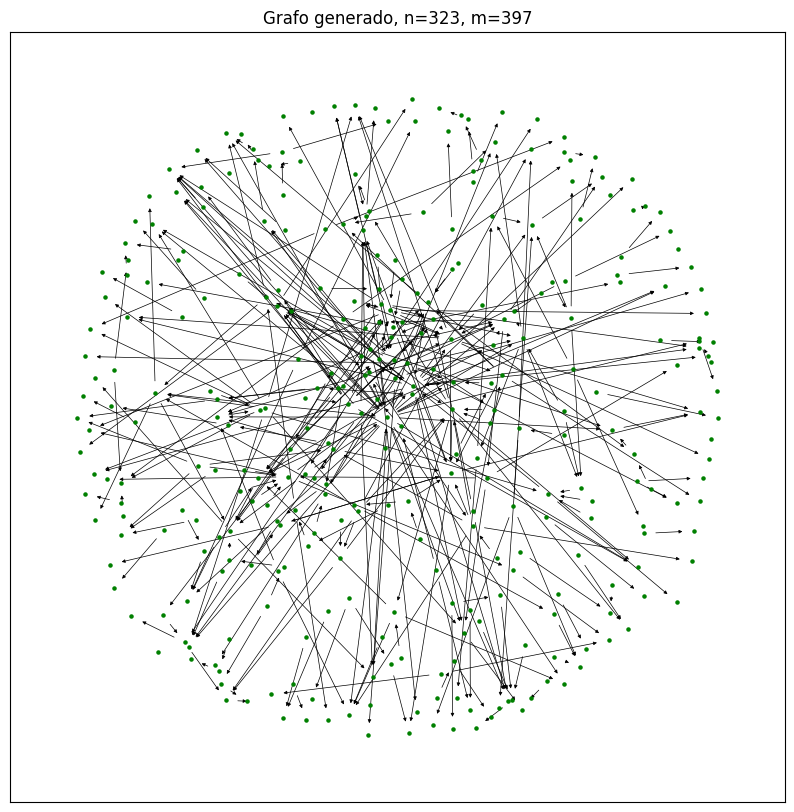

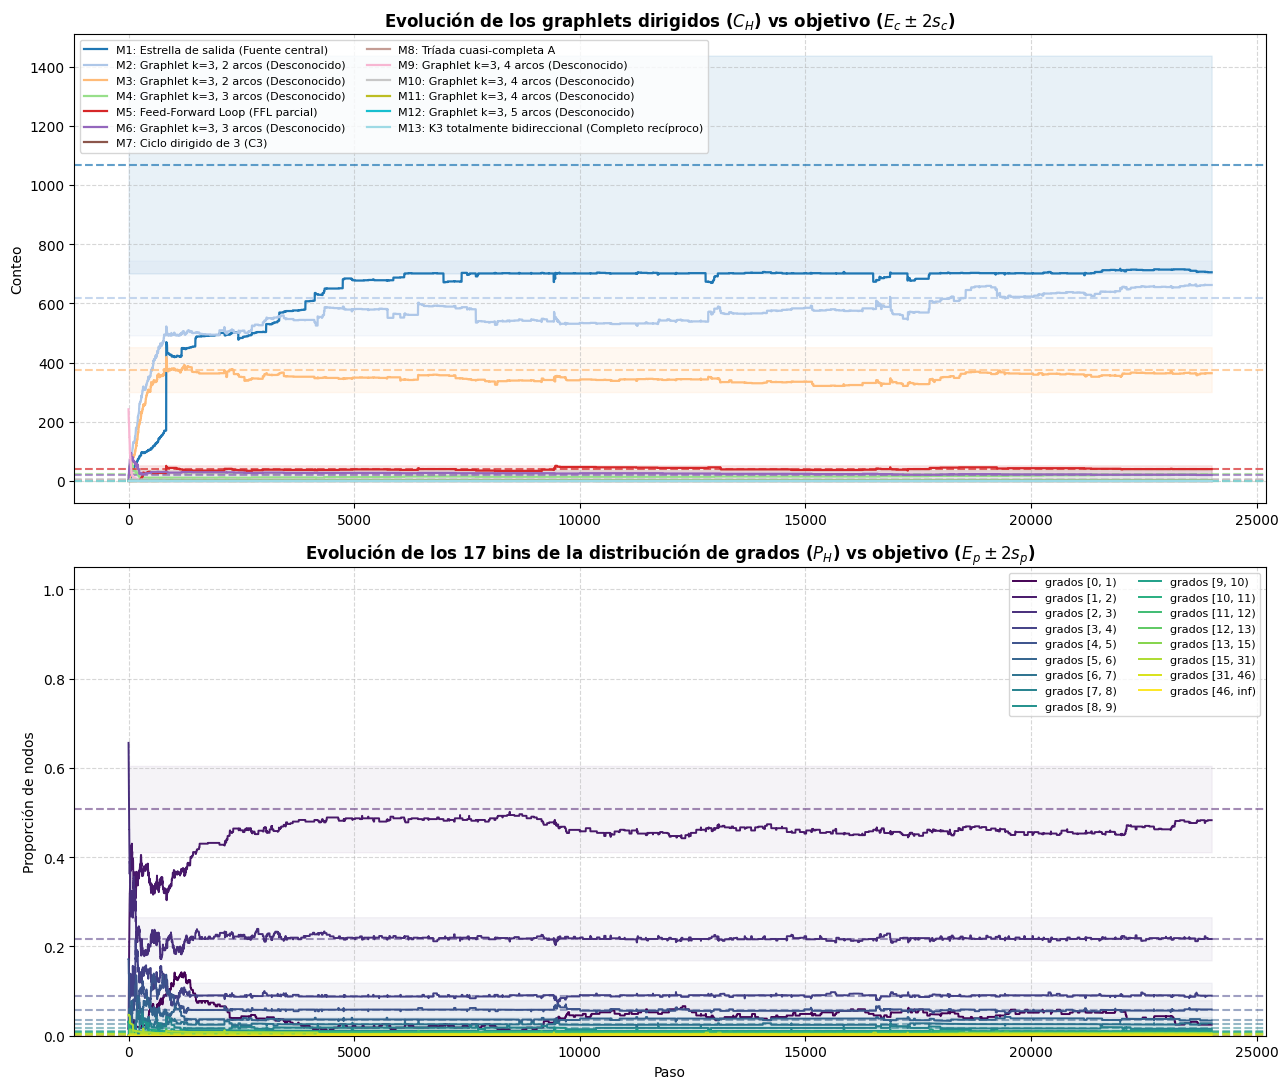

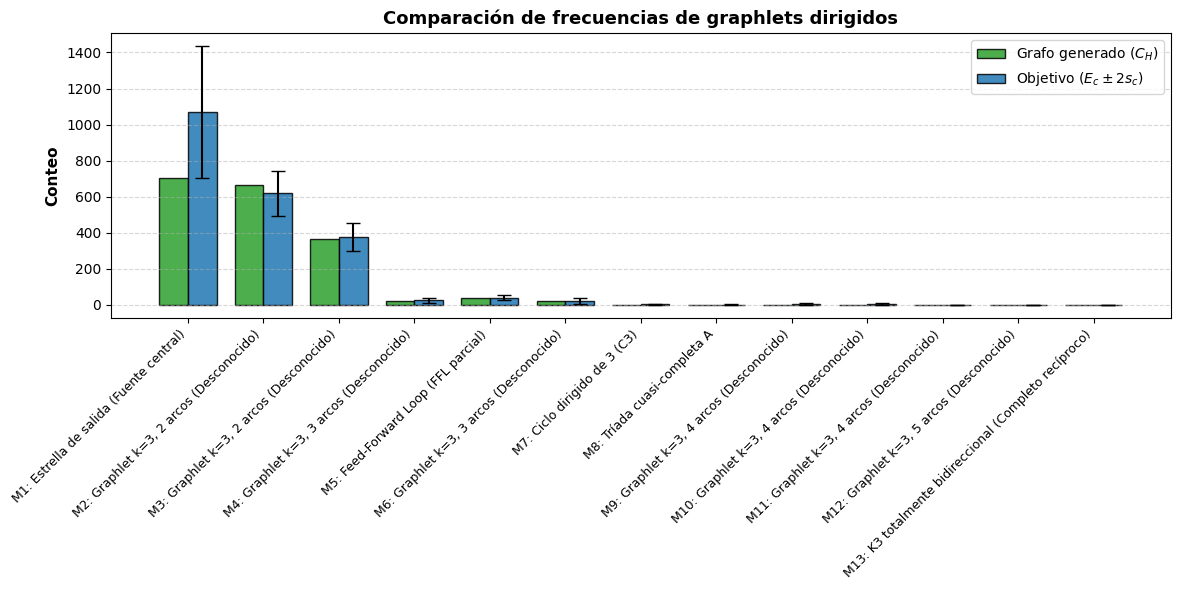

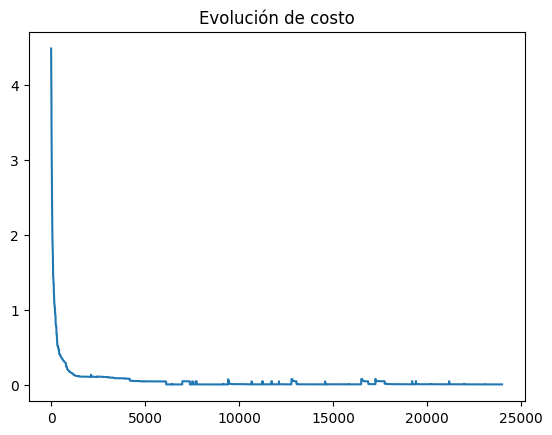

In [ ]:
n=history_data['n_trajectory'][-1]
m=history_data['m_trajectory'][-1]

plt.figure(figsize=(10, 10))
plt.title(f'Grafo generado, n={n}, m={m}')
nx.draw_networkx_nodes(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.15),node_color="green",node_size=5)
nx.draw_networkx_edges(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.15),edge_color='black',width=0.5,arrowsize=5)
plt.show()

gdn.plot_parameters_evolution(history_data)

final_CH_counts = history_data['CH_trajectory'][-1]
gdn.plot_graphlet_bar_comparison(final_CH_counts, history_data)
cost_evolution= history_data['cost_trajectory']
plt.title('Evolución de costo')
plt.plot(cost_evolution)

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import networkx as nx

# 1. Extraer la lista de grafos del historial
graphs = history_data['graphs']
steps = history_data['steps']

print(f"Total de frames guardados para animar: {len(graphs)}")

# 2. Configurar la figura de Matplotlib
fig, ax = plt.subplots(figsize=(8, 8))

# 3. Calcular un layout fijo basado en el ÚLTIMO grafo (para que la estructura no "baile")
# Usamos el grafo final para encontrar las posiciones globales de todos los nodos que aparecieron
pos_global = nx.spring_layout(graphs[-1], seed=42, k=0.15)

i=0
def update(frame_idx):
    global i
    ax.clear()
    G_current = graphs[frame_idx]
    step_actual = steps[frame_idx]

    # Para asegurar que si un nodo es muy nuevo y no está en pos_global, no dé error:
    # (Aunque lo ideal es calcular el layout con el grafo final)
    pos = {node: pos_global[node] for node in G_current.nodes() if node in pos_global}

    # Si algún nodo es nuevo y no estaba en el final, le asignamos una posición temporal
    for node in G_current.nodes():
        if node not in pos:
            pos[node] = (0.0, 0.0)

    # Dibujar el grafo actual
    nx.draw_networkx_nodes(G_current, pos, ax=ax, node_size=10, node_color='blue')
    nx.draw_networkx_edges(G_current, pos, ax=ax, alpha=1, edge_color='black', width=0.5,arrowsize=5)

    # Mostrar información en el título de la animación
    n_nodos = G_current.number_of_nodes()
    n_aristas = G_current.number_of_edges()
    costo_actual = history_data['cost_trajectory'][frame_idx]

    ax.set_title(f"Paso: {step_actual} | Nodos: {n_nodos} | Aristas: {n_aristas} | Costo: {costo_actual:.4f}", fontsize=12)
    ax.axis('off')
    i+=1
    print(i)

# 4. Crear la animación (interval controla la velocidad en milisegundos entre frames)
ani = animation.FuncAnimation(fig, update, frames=len(graphs), interval=50, repeat=False)

plt.close(fig) # Evita que se dibuje una figura estática extra al final del script

# 5. Renderizar y reproducir la animación en Google Colab
HTML(ani.to_html5_video())

Total de frames guardados para animar: 1254
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266


## animacion nautili

In [ ]:
# 3. Cárgalo de vuelta a NetworkX
G_core = nx.read_graphml('/content/grafo_proteinas_probabilista7.graphml')
print(
    f"✨ ¡Grafo cargado exitosamente! Nodos: {G_core.number_of_nodes()},"
    f" Aristas: {G_core.number_of_edges()}"
)

In [ ]:
pesos_aristas = [G_core[u][v]["prob"] for u, v,data in G_core.edges(data=True)]

plt.figure(figsize=(10, 10))
nx.draw_networkx_nodes(G_core,nx.spring_layout(G_core, seed=42,k=0.15),node_color="red",node_size=5)
nx.draw_networkx_edges(G_core,nx.spring_layout(G_core, seed=42,k=0.15),alpha=pesos_aristas,edge_color='black',width=1)
plt.show()

In [ ]:
G = G_core
S = 1000      # el paper usa 10 000 muestras
ng = 4

SAMPLE = gpn.Sample(G, S, ng, seed=0)
print(f"En = {SAMPLE['En']:.2f} ± {SAMPLE['sn']:.2f}   Em = {SAMPLE['Em']:.2f} ± {SAMPLE['sm']:.2f}   CCg = {SAMPLE['CCg']:.3f}")
for nombre, e, s in zip(SAMPLE["cat"]["nombres"], SAMPLE["Ec"], SAMPLE["sc"]):
    print(f"  {nombre:18s} Ec = {e:8.1f}  ± 2sc = {2*s:7.1f}")

In [ ]:
# Ejecutar GraphGenerator con los parámetros recomendados en el paper
# (node_step = 5, w = 2/3, maxrej = 0.02·Em, intervalo E ± 2s)
synthetic_H, history_data = GraphGenerator_animar(
    SAMPLE, ng,  maxs=50000, node_step=100, w=2/3, maxrej=200, K=2, seed=0, verbose=2000
)

In [ ]:
n=history_data['n_trajectory'][-1]
m=history_data['m_trajectory'][-1]

plt.figure(figsize=(10, 10))
plt.title(f'Grafo generado, n={n}, m={m}')
nx.draw_networkx_nodes(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.15),node_color="green",node_size=5)
nx.draw_networkx_edges(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.15),edge_color='black',width=0.5,arrowsize=5)
plt.show()

gdn.plot_parameters_evolution(history_data)

final_CH_counts = history_data['CH_trajectory'][-1]
gdn.plot_graphlet_bar_comparison(final_CH_counts, history_data)
cost_evolution= history_data['cost_trajectory']
plt.title('Evolución de costo')
plt.plot(cost_evolution)

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import networkx as nx

# 1. Extraer la lista de grafos del historial
graphs = history_data['graphs']
steps = history_data['steps']

print(f"Total de frames guardados para animar: {len(graphs)}")

# 2. Configurar la figura de Matplotlib
fig, ax = plt.subplots(figsize=(8, 8))

# 3. Calcular un layout fijo basado en el ÚLTIMO grafo (para que la estructura no "baile")
# Usamos el grafo final para encontrar las posiciones globales de todos los nodos que aparecieron
pos_global = nx.spring_layout(graphs[-1], seed=42, k=0.15)

i=0
def update(frame_idx):
    global i
    ax.clear()
    G_current = graphs[frame_idx]
    step_actual = steps[frame_idx]

    # Para asegurar que si un nodo es muy nuevo y no está en pos_global, no dé error:
    # (Aunque lo ideal es calcular el layout con el grafo final)
    pos = {node: pos_global[node] for node in G_current.nodes() if node in pos_global}

    # Si algún nodo es nuevo y no estaba en el final, le asignamos una posición temporal
    for node in G_current.nodes():
        if node not in pos:
            pos[node] = (0.0, 0.0)

    # Dibujar el grafo actual
    nx.draw_networkx_nodes(G_current, pos, ax=ax, node_size=10, node_color='blue')
    nx.draw_networkx_edges(G_current, pos, ax=ax, alpha=1, edge_color='black', width=0.5)

    # Mostrar información en el título de la animación
    n_nodos = G_current.number_of_nodes()
    n_aristas = G_current.number_of_edges()
    costo_actual = history_data['cost_trajectory'][frame_idx]

    ax.set_title(f"Paso: {step_actual} | Nodos: {n_nodos} | Aristas: {n_aristas} | Costo: {costo_actual:.4f}", fontsize=12)
    ax.axis('off')
    i+=1
    print(i)

# 4. Crear la animación (interval controla la velocidad en milisegundos entre frames)
ani = animation.FuncAnimation(fig, update, frames=len(graphs), interval=100, repeat=False)

plt.close(fig) # Evita que se dibuje una figura estática extra al final del script

# 5. Renderizar y reproducir la animación en Google Colab
HTML(ani.to_html5_video())